# 03 — LoRA à la main, sur notre mini-GPT

**Chapitre 3** · durée conseillée : 35 min · CPU : ≈ 3 min de pré-entraînement (ou chargement instantané du checkpoint) + ≈ 2 min de fine-tuning · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/chapitre_3/03_lora_a_la_main.ipynb)

![Parcours du chapitre 3](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_3/figures/00_parcours.png)

Fine-tuner Mistral 7B « normalement » (*full fine-tuning*) demande de stocker un gradient et deux états AdamW pour **7 milliards** de paramètres : plus de 80 Go (notebook 04). **LoRA** (*Low-Rank Adaptation*, Hu et al. 2021) contourne le problème : on **gèle** tous les poids et on apprend seulement une petite **correction de faible rang**.

Avant de l'utiliser sur Mistral (notebook 05), nous allons **l'implémenter nous-mêmes** et la tester sur le mini-GPT du chapitre 2, sur CPU. Le scénario reproduit exactement celui du chapitre :

> un modèle **pré-entraîné** sur un grand corpus (Platon, 4 M de caractères) → **fine-tuné** sur un petit corpus (Kaamelott, 3 000 caractères).

**À la fin de ce notebook, vous saurez :**
1. expliquer l'équation `W = W₀ + (α/r)·BA` et pourquoi `B` est initialisée à zéro ;
2. écrire une couche `LoRALinear` et l'insérer dans un modèle existant ;
3. compter les paramètres entraînables d'un LoRA ;
4. comparer **entraînement de zéro**, **full fine-tuning** et **LoRA** sur la loss Kaamelott **et** sur l'**oubli** de Platon ;
5. fusionner un adapter dans le modèle (`merge`) et retrouver la même chose avec la bibliothèque `peft`.

In [1]:
# Préparation. Sur Colab : on récupère le dépôt du cours (données + modules partagés).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("finetune.py"):
    !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/chapitre_3
sys.path.insert(0, "../chapitre_2")   # minigpt.py du chapitre 2

import math, random, warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # avertissement tqdm sans importance
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import finetune as ft   # fichier finetune.py, à côté de ce notebook
torch.manual_seed(1337)
print("PyTorch", torch.__version__)
import copy, time
from pathlib import Path
import minigpt

PyTorch 2.15.0+cu132


## 1. L'idée : une correction de faible rang

![LoRA](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_3/figures/03_lora.png)

Pendant un fine-tuning complet, chaque matrice de poids `W₀` (taille `d × k`) devient `W₀ + ΔW`. L'hypothèse de LoRA : pour **adapter** un modèle déjà compétent, la correction `ΔW` n'a pas besoin d'être quelconque ; elle peut être de **faible rang** `r`, donc s'écrire comme le produit de deux matrices fines :

$$W = W_0 + \frac{\alpha}{r}\,B A, \qquad B \in \mathbb{R}^{d\times r},\; A \in \mathbb{R}^{r\times k},\; r \ll \min(d,k)$$

- `A` est initialisée **au hasard**, `B` à **zéro** : au départ `BA = 0`, le modèle est **exactement** le modèle pré-entraîné. L'entraînement part du modèle, pas d'un modèle abîmé par du bruit.
- `α/r` est un facteur d'échelle : il permet de changer `r` sans retoucher le learning rate.
- Pour `d = k = 4096` et `r = 16` : `16 × (4096 + 4096) = 131 072` paramètres au lieu de `16 777 216`.

Un produit `BA` a un rang au plus `r`, quelle que soit la taille de la matrice :

In [2]:
B = torch.randn(6, 2)
A = torch.randn(2, 5)
delta = B @ A
print("ΔW = B @ A, forme", tuple(delta.shape), "| rang :", torch.linalg.matrix_rank(delta).item())
print(f"paramètres : B et A = {B.numel() + A.numel()} au lieu de {delta.numel()}")

for r in [1, 4, 16, 64]:
    d = k = 4096
    print(f"r = {r:3d} : {r * (d + k):>10,} paramètres pour une matrice 4096 x 4096 ({r * (d + k) / (d * k):6.2%})")

ΔW = B @ A, forme (6, 5) | rang : 2
paramètres : B et A = 22 au lieu de 30
r =   1 :      8,192 paramètres pour une matrice 4096 x 4096 ( 0.05%)
r =   4 :     32,768 paramètres pour une matrice 4096 x 4096 ( 0.20%)
r =  16 :    131,072 paramètres pour une matrice 4096 x 4096 ( 0.78%)
r =  64 :    524,288 paramètres pour une matrice 4096 x 4096 ( 3.12%)


## 2. La couche `LoRALinear`

On **enveloppe** un `nn.Linear` existant : sa sortie est inchangée, on y **ajoute** le chemin `x → A → B`. Ce code est identique à `finetune.LoRALinear`.

In [3]:
class LoRALinear(nn.Module):
    """y = W0 x + (alpha / r) · B A x, avec W0 gelé, A (r, in) aléatoire, B (out, r) nul au départ."""

    def __init__(self, base: nn.Linear, r=4, alpha=8, dropout=0.0):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad_(False)                       # W0 (et le biais) : gelés
        self.r, self.scale = r, alpha / r
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))   # ΔW = BA = 0 au départ
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scale * (self.dropout(x) @ self.A.T @ self.B.T)

    def delta_w(self):
        return self.scale * self.B @ self.A


torch.manual_seed(0)
lin = nn.Linear(64, 16)
lora = LoRALinear(lin, r=4, alpha=8)
x = torch.randn(3, 64)
print("au départ, même sortie que la couche d'origine :", torch.allclose(lora(x), lin(x)))
print("paramètres entraînables :", [(n, tuple(p.shape)) for n, p in lora.named_parameters() if p.requires_grad])
print("paramètres gelés        :", [(n, tuple(p.shape)) for n, p in lora.named_parameters() if not p.requires_grad])

au départ, même sortie que la couche d'origine : True
paramètres entraînables : [('A', (4, 64)), ('B', (16, 4))]
paramètres gelés        : [('base.weight', (16, 64)), ('base.bias', (16,))]


Pour l'insérer dans un modèle, on parcourt ses sous-modules et on remplace les `nn.Linear` **ciblés** par leur nom. Dans notre mini-GPT, les projections d'attention s'appellent `query`, `key`, `value` (classe `Head`) et `proj` (classe `MultiHeadAttention`) ; dans Mistral, ce sont `q_proj`, `k_proj`, `v_proj`, `o_proj`. Le papier LoRA original ciblait seulement **q et v**.

`ft.appliquer_lora(model, cibles, r, alpha)` gèle tout le modèle, puis fait ce remplacement.

In [4]:
demo = minigpt.GPTLanguageModel(vocab_size=100, block_size=64, n_embd=64, n_head=4, n_layer=4)
avant = ft.compter_parametres(demo)
remplaces = ft.appliquer_lora(demo, cibles=("query", "value"), r=4, alpha=8)
print(f"{len(remplaces)} couches enveloppées, par ex. {remplaces[:3]}")
print(f"paramètres totaux       : {ft.compter_parametres(demo):,} (dont {avant:,} d'origine)")
print(f"paramètres entraînables : {ft.compter_parametres(demo, entrainables_seulement=True):,}")

32 couches enveloppées, par ex. ['blocks.0.sa.heads.0.query', 'blocks.0.sa.heads.0.value', 'blocks.0.sa.heads.1.query']
paramètres totaux       : 226,532 (dont 216,292 d'origine)
paramètres entraînables : 10,240


---
## 3. Un « modèle de fondation » de poche : le mini-GPT pré-entraîné sur Platon

On reprend **exactement** le mini-GPT du notebook 09 du chapitre 2 (4 blocs, 4 têtes, `n_embd = 64`), entraîné 3 000 pas sur Platon. Une différence : le vocabulaire est construit sur Platon **et** Kaamelott, pour que le modèle puisse écrire les caractères de Kaamelott (`’` notamment). Un vrai LLM n'a pas ce problème : son vocabulaire BPE couvre toutes les langues qu'il a vues.

Le pré-entraînement prend ≈ 3 min sur un portable ; le résultat est sauvegardé dans `checkpoints/minigpt_platon.pt` et rechargé ensuite.

In [5]:
platon = ft.charger_texte("platon")
g_train, g_val = ft.separer_par_groupe(ft.lire_dialogues("kaamelott", nettoyage=False), part_val=0.2, graine=42)
en_texte = lambda gs: "\n\n".join("\n".join(f"{r.personnage}: {r.texte.strip()}" for r in g) for g in gs) + "\n"
kaam_train, kaam_val = en_texte(g_train), en_texte(g_val)     # mêmes scènes qu'au notebook 02

chars = sorted(set(platon) | set(kaam_train) | set(kaam_val))
stoi = {c: i for i, c in enumerate(chars)}
V = len(chars)
encode = lambda s: torch.tensor([stoi[c] for c in s], dtype=torch.long)
decode = lambda ids: "".join(chars[int(i)] for i in ids)

P = encode(platon)
n = int(0.9 * len(P))
platon_train, platon_val = P[:n], P[n:]
K_train, K_val = encode(kaam_train), encode(kaam_val)
print(f"V = {V} | Platon : {len(platon_train):,} / {len(platon_val):,} | Kaamelott : {len(K_train):,} / {len(K_val):,} caractères")

B_, T_, C_, H_, L_ = 32, 64, 64, 4, 4
CKPT = Path("checkpoints/minigpt_platon.pt")
torch.manual_seed(1337)
base = minigpt.GPTLanguageModel(V, T_, C_, H_, L_, dropout=0.1)
if CKPT.exists() and torch.load(CKPT)["chars"] == chars:
    base.load_state_dict(torch.load(CKPT)["state_dict"])
    print("checkpoint chargé :", CKPT)
else:
    opt = torch.optim.AdamW(base.parameters(), lr=1e-3)
    debut = time.time()
    for it in range(3001):
        if it % 500 == 0:
            p = minigpt.estimate_loss(base, platon_train, platon_val, B_, T_)
            print(f"pas {it:4d} | train {p['train']:.3f} | val {p['val']:.3f} | {time.time() - debut:4.0f} s")
        xb, yb = minigpt.get_batch(platon_train, B_, T_)
        _, loss = base(xb, yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    CKPT.parent.mkdir(exist_ok=True)
    torch.save({"chars": chars, "state_dict": base.state_dict()}, CKPT)
base.eval()

torch.manual_seed(0)
print("\n--- le modèle pré-entraîné, amorcé par « ARTHUR: » ---")
print(decode(base.generate(encode("ARTHUR:").unsqueeze(0), 250)[0]))

V = 114 | Platon : 3,503,608 / 389,290 | Kaamelott : 3,110 / 1,126 caractères
checkpoint chargé : checkpoints/minigpt_platon.pt

--- le modèle pré-entraîné, amorcé par « ARTHUR: » ---


ARTHUR:
J'à mettre qu'il nous a mejourais ce vient à qui ne ne sera en qu'elle avait, et n'est.

L'ÉTRANGER:
Et qu'il a partaité en en viense à la tert, ne voudrer peut qui pas point facrit du commes ; nécrin craint, le partiquent, la même à comme en lui et


Le modèle « parle Platon » : français du XIXᵉ siècle, noms en majuscules suivis de `:` et d'un retour à la ligne. Il ne connaît rien de Kaamelott.

---
## 4. L'expérience : quatre façons d'apprendre Kaamelott

| Variante | Point de départ | Paramètres entraînés | lr |
|---|---|---|---|
| **De zéro** | poids aléatoires | tous | 1e-3 |
| **Full fine-tuning** | modèle Platon | tous | 1e-4 (10 × plus petit : on part d'un bon modèle) |
| **LoRA q, v** (r = 4) | modèle Platon | A et B sur `query`, `value` | 3e-3 |
| **LoRA partout** (r = 4) | modèle Platon | A et B sur toutes les linéaires des blocs | 3e-3 |

Le learning rate de LoRA est **plus grand** : seules de petites matrices partant de zéro sont apprises (TRL recommande 2e-4 pour LoRA sur un 7B, contre ~1e-5 pour un full fine-tuning).

Tous les 50 pas, on mesure deux choses :
- la loss de **validation Kaamelott** (scènes jamais vues) : a-t-on appris Kaamelott ?
- la loss de **validation Platon** : a-t-on **oublié** Platon ?

In [6]:
@torch.no_grad()
def mesurer(model):
    k = minigpt.estimate_loss(model, K_train, K_val, B_, T_, eval_iters=20)["val"]
    p = minigpt.estimate_loss(model, platon_train, platon_val, B_, T_, eval_iters=20)["val"]
    return k, p

def affiner(model, lr, iters=300, tous_les=50):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr)
    hist = {"pas": [], "kaamelott": [], "platon": []}
    for it in range(iters + 1):
        if it % tous_les == 0:
            k, p = mesurer(model)
            hist["pas"].append(it); hist["kaamelott"].append(k); hist["platon"].append(p)
        xb, yb = minigpt.get_batch(K_train, B_, T_)
        _, loss = model(xb, yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    model.eval()
    return hist

variantes = {}
debut = time.time()

torch.manual_seed(0)
zero = minigpt.GPTLanguageModel(V, T_, C_, H_, L_, dropout=0.1)
variantes["de zéro"] = (zero, affiner(zero, lr=1e-3))

torch.manual_seed(0)
full = copy.deepcopy(base); full.train()
variantes["full fine-tuning"] = (full, affiner(full, lr=1e-4))

torch.manual_seed(0)
lora_qv = copy.deepcopy(base); lora_qv.train()
ft.appliquer_lora(lora_qv, cibles=("query", "value"), r=4, alpha=8)
variantes["LoRA q,v r=4"] = (lora_qv, affiner(lora_qv, lr=3e-3))

torch.manual_seed(0)
lora_all = copy.deepcopy(base); lora_all.train()
# "0" et "2" : les deux nn.Linear du FeedForward (nn.Sequential numérote ses couches)
ft.appliquer_lora(lora_all, cibles=("query", "key", "value", "proj", "0", "2"), r=4, alpha=8)
variantes["LoRA partout r=4"] = (lora_all, affiner(lora_all, lr=3e-3))

print(f"4 variantes entraînées en {time.time() - debut:.0f} s\n")
k0, p0 = mesurer(base)
print(f"{'variante':18s} {'entraînables':>12s} {'meilleure val Kaam.':>20s} {'val Platon (fin)':>17s}")
print(f"{'modèle Platon':18s} {0:12,} {k0:20.3f} {p0:17.3f}")
for nom, (m, h) in variantes.items():
    print(f"{nom:18s} {ft.compter_parametres(m, True):12,} {min(h['kaamelott']):20.3f} {h['platon'][-1]:17.3f}")

4 variantes entraînées en 113 s



variante           entraînables  meilleure val Kaam.  val Platon (fin)
modèle Platon                 0                2.494             1.464
de zéro                 218,098                2.153             2.849
full fine-tuning        218,098                1.622             1.731
LoRA q,v r=4             10,240                1.834             1.838
LoRA partout r=4         27,648                1.693             2.153


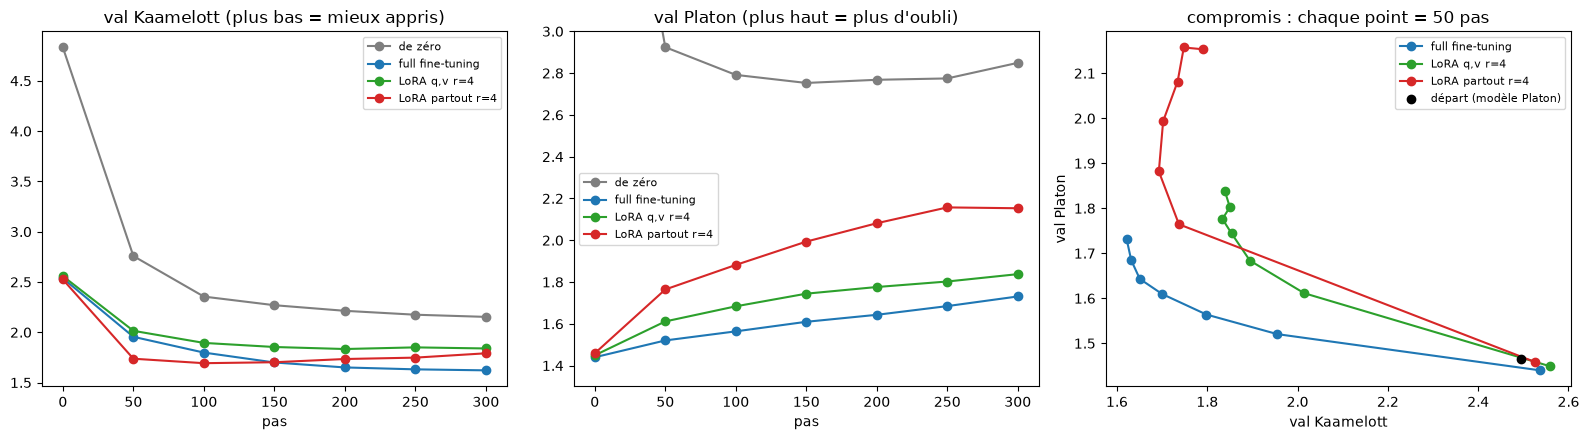

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
couleurs = dict(zip(variantes, ["tab:gray", "tab:blue", "tab:green", "tab:red"]))
for nom, (m, h) in variantes.items():
    axes[0].plot(h["pas"], h["kaamelott"], marker="o", label=nom, color=couleurs[nom])
    axes[1].plot(h["pas"], h["platon"], marker="o", label=nom, color=couleurs[nom])
    if nom != "de zéro":
        axes[2].plot(h["kaamelott"], h["platon"], marker="o", label=nom, color=couleurs[nom])
axes[0].set_title("val Kaamelott (plus bas = mieux appris)"); axes[0].set_xlabel("pas")
axes[1].set_title("val Platon (plus haut = plus d'oubli)"); axes[1].set_xlabel("pas")
axes[1].set_ylim(1.3, 3.0)
axes[2].set_title("compromis : chaque point = 50 pas"); axes[2].set_xlabel("val Kaamelott"); axes[2].set_ylabel("val Platon")
axes[2].scatter([k0], [p0], color="black", zorder=5, label="départ (modèle Platon)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Ce qu'il faut lire :**

1. **De zéro**, le modèle plafonne vers 2,15 : 3 000 caractères ne suffisent pas pour apprendre une langue. (Sa loss Platon est mauvaise, mais normal : il n'a jamais vu Platon.)
2. **Partir d'un modèle pré-entraîné change tout** : les trois variantes fine-tunées passent sous 1,85 en moins de 150 pas. Le modèle sait déjà le français ; il n'apprend que le **style** Kaamelott (noms sur la même ligne, `’`, registre familier).
3. **LoRA q,v** y arrive avec **10 240** paramètres entraînables (≈ 5 % du modèle ici ; < 1 % sur Mistral 7B).
4. **Mais LoRA ne gagne pas ici sur la qualité.** Sur le graphique de droite, pour un même niveau sur Kaamelott, le full fine-tuning (lr 1e-4, prudent) oublie **moins** Platon que nos LoRA (lr 3e-3, agressif). Le réglage du learning rate compte autant que la méthode. Sur les grands modèles, les études concluent que *« LoRA learns less and forgets less »* (Biderman et al., 2024) aux réglages usuels, sans dominer le full fine-tuning.
5. **L'avantage de LoRA est ailleurs** : pas de gradient ni d'état AdamW pour les poids gelés (la **mémoire**, notebook 04) et un **adapter** de quelques ko à sauvegarder (§5). Sur Mistral 7B, c'est la différence entre « impossible sur un GPU » et « possible sur Colab ».
6. Plus on adapte de couches (**LoRA partout**), plus on apprend vite… et plus on oublie : sa loss Kaamelott remonte dès 100 pas (surapprentissage). En pratique on garde le **meilleur checkpoint** (arrêt anticipé), et surtout on **ajoute des données**.

### Écouter les modèles

In [8]:
amorce = encode("ARTHUR:").unsqueeze(0)
for nom, m in [("modèle Platon", base)] + [(n, m) for n, (m, h) in variantes.items()]:
    torch.manual_seed(1)
    print(f"--- {nom} ---")
    print(decode(m.generate(amorce, 200, temperature=0.8)[0]))
    print()

--- modèle Platon ---


ARTHUR:
SOCRATE:
Tu manision. noteront de doit ens connilité objet de litueur et aux demanitures et en aux autres autres dout pourquer, suit à les terdre sente, le même de cornore il se ne saissemble autre d

--- de zéro ---


ARTHUR: Mans ças, ?

ARAR: Ma Manous la lllà ?
PERCEVAL: ALEVAL: vasasa va dez sa le l’entonsez ller d’e que couxe les ? se Mon ari, l’ouen ce Pa quilasies mon se le ast quade e a les e llesontrit de llèt as

--- full fine-tuning ---


ARTHUR: Al autre là sortrière à nous la vaise sera salon peu maint que nous on sa troit !
PERTHUR: Si son non nous on vous foir leurs vous rond là dire des moucrant là troin ?
LEODAGAN: Ou Oh part de là cons

--- LoRA q,v r=4 ---


ARTHUR: Al sont plus de rien étant lle de là dans, sôlez peu est que sans dis le vous con de compler de conger ; On cons sûn son et le sort change dire, est on sans pas qui est bal, a vous le partait le fais

--- LoRA partout r=4 ---


ARTHUR: On saissez le cons deux nous les chands : Je que me condevage à vaixez sait incerse ; à la perse que tire on sens de le crille ? Alors dix dilà sinomencer de le connance à ï on plusse ; rager là-con 



Après le fine-tuning, le **format** change : nom et réplique sur la même ligne, noms de Kaamelott (`LEODAGAN`, `PERCEVAL`), points d'exclamation, `on`, `là`. Le modèle « de zéro » invente des noms (`ARAR`, `ALEVAL`) et des mots plus abîmés. Avec 200 000 paramètres, aucun ne produit des répliques sensées : c'est le **style** qu'on voit passer, pas l'humour. Pour l'humour, il faut un modèle qui sait déjà parler : Mistral 7B, notebook 05.

---
## 5. Ce qu'on sauvegarde, et la fusion

Avec LoRA, on ne sauvegarde **que l'adapter** (les A et B), pas le modèle :

In [9]:
adapter = {n: p for n, p in lora_qv.state_dict().items() if n.endswith((".A", ".B"))}
octets_adapter = sum(p.numel() * 4 for p in adapter.values())
octets_modele = sum(p.numel() * 4 for p in base.state_dict().values())
print(f"adapter : {len(adapter)} tenseurs, {octets_adapter / 1e3:.0f} ko | modèle complet : {octets_modele / 1e3:.0f} ko")
print("Sur Mistral 7B (r = 16, toutes les linéaires) : ~160 Mo d'adapter contre 14,5 Go de modèle.")

adapter : 64 tenseurs, 41 ko | modèle complet : 1135 ko
Sur Mistral 7B (r = 16, toutes les linéaires) : ~160 Mo d'adapter contre 14,5 Go de modèle.


On peut garder **une base** et **plusieurs adapters** (Kaamelott, Platon, Shakespeare…) et les échanger à la volée. Pour le déploiement, on peut aussi **fusionner** : `W = W₀ + (α/r)·BA` est une matrice ordinaire, de la même taille que `W₀`. Le modèle fusionné n'a **aucun coût supplémentaire** à l'inférence — c'est ce que fait `merge_and_unload()` dans `peft` (notebook 07).

In [10]:
fusionne = copy.deepcopy(lora_qv)
for nom, module in list(fusionne.named_modules()):
    for nom_enfant, enfant in list(module.named_children()):
        if isinstance(enfant, ft.LoRALinear):
            setattr(module, nom_enfant, enfant.fusionner())     # nn.Linear avec W0 + ΔW

x = K_val[:T_].unsqueeze(0)
with torch.no_grad():
    ecart = (lora_qv(x)[0] - fusionne(x)[0]).abs().max().item()
print(f"écart max entre logits LoRA et logits fusionnés : {ecart:.2e}")
print("plus aucune couche LoRA :", not any(isinstance(m, ft.LoRALinear) for m in fusionne.modules()))
print("rang de ΔW d'une tête :", torch.linalg.matrix_rank(lora_qv.blocks[0].sa.heads[0].query.delta_w()).item())

écart max entre logits LoRA et logits fusionnés : 5.72e-06
plus aucune couche LoRA : True
rang de ΔW d'une tête : 4


---
## 6. La même chose avec la bibliothèque `peft`

Sur Mistral, on n'écrira pas `LoRALinear` à la main : la bibliothèque **`peft`** de Hugging Face fait exactement ce remplacement. Elle fonctionne aussi sur notre mini-GPT, puisqu'il est fait de `nn.Linear` :

In [11]:
try:
    from peft import LoraConfig, get_peft_model
except ImportError:
    print("peft n'est pas installé : pip install peft")
else:
    config = LoraConfig(r=4, lora_alpha=8, target_modules=["query", "value"], lora_dropout=0.0)
    modele_peft = get_peft_model(copy.deepcopy(base), config)
    modele_peft.print_trainable_parameters()
    print("à la main :", ft.compter_parametres(lora_qv, entrainables_seulement=True), "paramètres entraînables")
    print(modele_peft.base_model.model.blocks[0].sa.heads[0].query)

trainable params: 10,240 || all params: 228,338 || trainable%: 4.4846
à la main : 10240 paramètres entraînables
lora.Linear(
  (base_layer): Linear(in_features=64, out_features=16, bias=False)
  (lora_dropout): ModuleDict(
    (default): Identity()
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=64, out_features=4, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=4, out_features=16, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)


Même nombre de paramètres entraînables, même structure (`lora_A`, `lora_B`, `scaling = α/r`). Au notebook 05, la configuration sera :

```python
LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
           target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
```

## À retenir

- LoRA gèle `W₀` et apprend `ΔW = (α/r)·BA` de **rang r**. `B = 0` au départ : on part **exactement** du modèle pré-entraîné.
- Paramètres entraînables : `r·(d + k)` par matrice au lieu de `d·k`.
- **Partir d'un modèle pré-entraîné** est ce qui rend possible l'apprentissage d'un style avec quelques milliers de caractères.
- Plus on adapte, plus on apprend **et** plus on oublie : c'est un compromis, réglé par `r`, les **modules ciblés**, le lr et le nombre de pas. LoRA n'est pas « meilleur » que le full fine-tuning ; il est **beaucoup moins cher** en mémoire et en stockage.
- On sauvegarde un **adapter** léger ; on peut le **fusionner** sans coût d'inférence.

**Questions de vérification**
1. Que se passerait-il si on initialisait `A` **et** `B` au hasard ?
2. Combien de paramètres entraînables pour un LoRA r = 8 sur `q_proj` et `v_proj` de Mistral 7B (32 couches, `q_proj` : 4096 → 4096, `v_proj` : 4096 → 1024) ?
3. Pourquoi le learning rate du full fine-tuning est-il plus petit que celui de l'entraînement de zéro ?
4. Sur le graphique de compromis, quelle variante choisiriez-vous pour un modèle qui doit rester bon en Platon ? Et pour un modèle 100 % Kaamelott ? Pourquoi choisirait-on quand même LoRA pour Mistral 7B ?

**Expériences** (une variable à la fois) : LoRA q,v avec `lr = 1e-3` (rejoint-il la courbe du full fine-tuning ?) ; `r = 1` contre `r = 16` ; LoRA sur `query` seul ; full FT avec `lr = 1e-3` ; 1 000 pas au lieu de 300.